# Group 8 — SMS Spam Detection
## Integrated Experiment: TF-IDF + Logistic Regression and Sentence-BERT + Logistic Regression

**Course:** Natural Language Processing · **Section:** FA02 · **Group:** 8  
**Members:** Raneem Bahobail (2240002294) · Alaa Bughararah (2240005619)


**Workstream attribution**
- **Raneem:** UCI data loading, data checks, duplicate-aware splitting, TF-IDF feature extraction, Logistic Regression, and TF-IDF threshold selection.
- **Alaa:** Frozen Sentence-BERT encoder, Logistic Regression on sentence embeddings, SBERT threshold selection, and the comparative evaluation/visualizations.



## 0. Setup — Experiment Settings

The agreed threshold-selection rule is: **minimize False Positive Rate (FPR) on the development set, subject to Spam Recall being at least `MIN_SPAM_RECALL`**. Each model gets its own threshold, selected independently from its own development probabilities. The test set is used only after thresholds are frozen.



In [1]:
MIN_SPAM_RECALL = 0.90


SPAM_ASSOCIATED_KEYWORDS = ["free", "win", "urgent", "cash","offer","reply"]
CHALLENGE_KEYWORDS_CONFIRMED = True

RANDOM_STATE = 42
TEST_SIZE = 0.20
DEV_SIZE_OF_REMAINDER = 0.20
DEFAULT_THRESHOLD = 0.50

print("Minimum development Spam Recall:", MIN_SPAM_RECALL)
print("Candidate challenge keywords:", SPAM_ASSOCIATED_KEYWORDS)
print("Challenge keywords confirmed:", CHALLENGE_KEYWORDS_CONFIRMED)

Minimum development Spam Recall: 0.9
Candidate challenge keywords: ['free', 'win', 'urgent', 'cash', 'offer', 'reply']
Challenge keywords confirmed: True


## 1. Install and import libraries

In [2]:

%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib "sentence-transformers==6.3.0" "transformers>=5.0,<6.0" "huggingface-hub>=1.16.0,<3.0"


In [3]:
import re
import json
import hashlib
import zipfile
import urllib.request
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, f1_score,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_colwidth", 160)
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data — UCI SMS Spam Collection

In [4]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
ZIP_PATH = "sms_spam_collection.zip"
urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    data_filename = next(n for n in archive.namelist() if n.endswith("SMSSpamCollection"))
    with archive.open(data_filename) as data_file:
        df = pd.read_csv(data_file, sep="\t", header=None, names=["label", "text"], encoding="utf-8")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 3. Explore the dataset
Inspect class balance, missing values, and example messages.

In [5]:
print("Dataset information:")
df.info()
print("\nMissing values:")
display(df.isna().sum())
print("\nClass counts:")
display(df["label"].value_counts())
print("\nClass percentages:")
display((df["label"].value_counts(normalize=True) * 100).round(2))
print("\nHAM examples:")
display(df[df.label == "ham"][ ["text"] ].head(5))
print("\nSPAM examples:")
display(df[df.label == "spam"][ ["text"] ].head(5))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:


,0
label,0
text,0



Class counts:


,count
label,
ham,4825
spam,747



Class percentages:


,proportion
label,
ham,86.59
spam,13.41



HAM examples:


,text
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,Ok lar... Joking wif u oni...
3,U dun say so early hor... U c already then say...
4,"Nah I don't think he goes to usf, he lives around here though"
6,Even my brother is not like to speak with me. They treat me like aids patent.



SPAM examples:


,text
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
5,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"
8,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
9,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030
11,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 4 info"


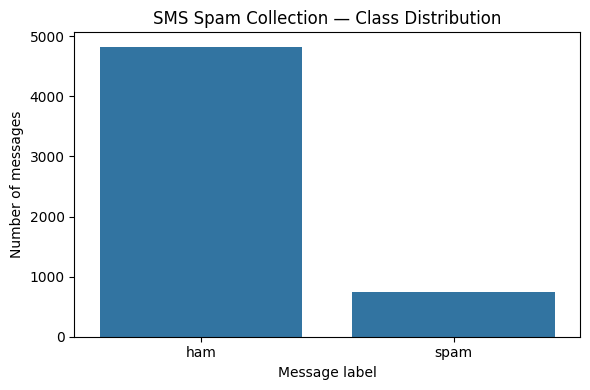

In [6]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"])
plt.title("SMS Spam Collection — Class Distribution")
plt.xlabel("Message label")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.show()

## 4. Clean labels and check duplicates


In [7]:
df = df.dropna(subset=["label", "text"]).copy()
df = df.reset_index(drop=True)
df["row_id"] = np.arange(len(df))
df["label"] = df["label"].astype(str).str.lower().str.strip()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])].copy()
df = df[df["text"] != ""].copy()
df["target"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

def normalize_for_duplicate_check(message):
    return re.sub(r"\s+", " ", str(message).strip().lower())

df["group_key"] = df["text"].apply(normalize_for_duplicate_check)
print("Rows after cleaning:", len(df))
print("Unique normalized message groups:", df.group_key.nunique())

Rows after cleaning: 5572
Unique normalized message groups: 5157


In [8]:
label_counts_per_group = df.groupby("group_key")["target"].nunique()
conflicting_groups = label_counts_per_group[label_counts_per_group > 1]
print("Duplicate groups with conflicting labels:", len(conflicting_groups))
if len(conflicting_groups) > 0:
    display(df[df.group_key.isin(conflicting_groups.index)][["label", "text", "group_key"]])
    raise ValueError("Review conflicting duplicate labels before proceeding.")

duplicate_summary = (df.groupby("group_key").size().reset_index(name="occurrences")
                        .query("occurrences > 1").sort_values("occurrences", ascending=False))
print("Repeated message groups:", len(duplicate_summary))
display(duplicate_summary.head(10))

Duplicate groups with conflicting labels: 0
Repeated message groups: 290


,group_key,occurrences
3799,"sorry, i'll call later",30
1825,i cant pick the phone right now. pls send a message,12
3270,ok...,10
3576,"say this slowly.? god,i love you &amp; i need you,clean my heart with your blood.send this to ten special people &amp; u c miracle tomorrow, do it,pls,pls d...",4
3249,ok.,4
3299,okie,4
3398,please call our customer service representative on freephone 0808 145 4742 between 9am-11pm as you have won a guaranteed £1000 cash or £5000 prize!,4
3171,ok,4
4549,"wen ur lovable bcums angry wid u, dnt take it seriously.. coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda man...",4
5082,your opinion about me? 1. over 2. jada 3. kusruthi 4. lovable 5. silent 6. spl character 7. not matured 8. stylish 9. simple pls reply..,4


## 5. Text preprocessing


In [9]:
df["model_text"] = df["text"]
display(df[["label", "text", "model_text"]].head(10))
print("Text preparation completed.")

,label,text,model_text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...","Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though","Nah I don't think he goes to usf, he lives around here though"
5,spam,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv","FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv"
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Caller...,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Caller...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030


Text preparation completed.


## 6. Create train/development/test splits
 Target proportions are approximately 64% training, 16% development, and 20% test. Stratification is performed on group labels; row proportions can differ slightly because groups may contain duplicate rows.

In [10]:
group_table = df.groupby("group_key", as_index=False).agg(target=("target", "first"))

train_dev_groups, test_groups = train_test_split(
    group_table, test_size=TEST_SIZE, random_state=RANDOM_STATE,
    stratify=group_table["target"]
)
train_groups, dev_groups = train_test_split(
    train_dev_groups, test_size=DEV_SIZE_OF_REMAINDER,
    random_state=RANDOM_STATE, stratify=train_dev_groups["target"]
)

train_keys = set(train_groups.group_key)
dev_keys = set(dev_groups.group_key)
test_keys = set(test_groups.group_key)
train_df = df[df.group_key.isin(train_keys)].copy().reset_index(drop=True)
dev_df = df[df.group_key.isin(dev_keys)].copy().reset_index(drop=True)
test_df = df[df.group_key.isin(test_keys)].copy().reset_index(drop=True)
print("Splits created.")

Splits created.


In [11]:
def describe_split(name, part):
    return {"Split": name, "Rows": len(part),
            "HAM": int((part.target == 0).sum()),
            "SPAM": int((part.target == 1).sum()),
            "Spam percentage": round(part.target.mean() * 100, 2)}

display(pd.DataFrame([describe_split("Training", train_df),
                      describe_split("Development", dev_df),
                      describe_split("Test", test_df)]))

assert train_keys.isdisjoint(dev_keys)
assert train_keys.isdisjoint(test_keys)
assert dev_keys.isdisjoint(test_keys)
for name, part in [("Training", train_df), ("Development", dev_df), ("Test", test_df)]:
    assert set(part.target.unique()) == {0, 1}, f"{name} is missing a class"
print("Checks passed: no duplicate group crosses splits; each split contains both labels.")

,Split,Rows,HAM,SPAM,Spam percentage
0,Training,3593,3117,476,13.25
1,Development,887,767,120,13.53
2,Test,1092,941,151,13.83


Checks passed: no duplicate group crosses splits; each split contains both labels.


In [12]:

splits = {
    "train": train_df.copy().reset_index(drop=True),
    "development": dev_df.copy().reset_index(drop=True),
    "test": test_df.copy().reset_index(drop=True),
}
shared_split_assignments = pd.concat(
    [part.assign(split=name) for name, part in splits.items()],
    ignore_index=True
)

# Integration checks: both models must receive the exact same rows.
assert shared_split_assignments.groupby("group_key")["split"].nunique().eq(1).all()
assert shared_split_assignments["label"].map({"ham": 0, "spam": 1}).eq(
    shared_split_assignments["target"]
).all()
assert all(set(part["target"].unique()) == {0, 1} for part in splits.values())

print("Integrated split rows:", len(shared_split_assignments))
print("Split counts:", {name: len(part) for name, part in splits.items()})
display(pd.crosstab(shared_split_assignments["split"], shared_split_assignments["label"]))

Integrated split rows: 5572
Split counts: {'train': 3593, 'development': 887, 'test': 1092}


label,ham,spam
split,,
development,767,120
test,941,151
train,3117,476


## 7. Method 1 — TF-IDF + Logistic Regression
TF-IDF converts text to numerical features. Unigrams are single words; bigrams are consecutive two-word phrases. The vectorizer is fitted on training text only. Development and test use the already-fitted transformation.

In [13]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df["model_text"])
X_dev_tfidf = tfidf_vectorizer.transform(dev_df["model_text"])
X_test_tfidf = tfidf_vectorizer.transform(test_df["model_text"])

print("Training matrix:", X_train_tfidf.shape)
print("Development matrix:", X_dev_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

Training matrix: (3593, 36287)
Development matrix: (887, 36287)
Test matrix: (1092, 36287)
Vocabulary size: 36287


## 8. Train Logistic Regression
The model learns to classify TF-IDF features as 0 = HAM / Not Spam and 1 = SPAM. It is trained using the training split only.

In [14]:
tfidf_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tfidf_model.fit(X_train_tfidf, train_df["target"])
print("TF-IDF + Logistic Regression trained.")
print("Model classes:", tfidf_model.classes_)

TF-IDF + Logistic Regression trained.
Model classes: [0 1]


## 9. Generate development spam probabilities
`predict_proba` returns a probability for each class. We extract the probability for class 1 (SPAM); this lets us change the decision threshold later.

In [15]:
spam_class_index = list(tfidf_model.classes_).index(1)
tfidf_dev_probabilities = tfidf_model.predict_proba(X_dev_tfidf)[:, spam_class_index]

print("First 10 development spam probabilities:")
print(np.round(tfidf_dev_probabilities[:10], 4))
print("Number of development probabilities:", len(tfidf_dev_probabilities))

First 10 development spam probabilities:
[0.454  0.0455 0.0511 0.0773 0.1073 0.0466 0.0665 0.866  0.0491 0.3528]
Number of development probabilities: 887


In [16]:
dev_predictions = pd.DataFrame({
    "text": dev_df["text"].values,
    "true_label": dev_df["label"].values,
    "true_target": dev_df["target"].values,
    "spam_probability": tfidf_dev_probabilities
})
display(dev_predictions.head(10))

,text,true_label,true_target,spam_probability
0,"XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL",spam,1,0.453977
1,Oh k...i'm watching here:),ham,0,0.045484
2,Is that seriously how you spell his name?,ham,0,0.051059
3,Lol your always so convincing.,ham,0,0.077295
4,For fear of fainting with the of all that housework you just did? Quick have a cuppa,ham,0,0.107251
5,Yup... Ok i go home look at the timings then i msg ü again... Xuhui going to learn on 2nd may too but her lesson is at 8am,ham,0,0.046571
6,I see the letter B on my car,ham,0,0.066534
7,07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a free nokia mobile + free camcorder. Please call now 08000930705 for d...,spam,1,0.866045
8,"Wow. I never realized that you were so embarassed by your accomodations. I thought you liked it, since i was doing the best i could and you always seemed so...",ham,0,0.049114
9,"Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all 4 FREE! bx420-ip4-5we. 150pm. Dont miss ...",spam,1,0.352760


## 10. Define evaluation metrics
For this project, SPAM is the positive class (1).
- FPR = FP / (FP + TN)
- Spam Recall = TP / (TP + FN)
- Accuracy = correct predictions / all predictions
- Macro F1 = average F1 across HAM and SPAM, weighting both classes equally.

In [17]:

def evaluate_threshold(y_true, spam_probabilities, threshold):

    y_true = np.asarray(y_true).astype(int)

    # Convert probabilities into predictions
    y_pred = (spam_probabilities >= threshold).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # False Positive Rate
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    # Spam Recall
    spam_recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    return {
        "Threshold": threshold,
        "FPR": fpr,
        "Spam Recall": spam_recall,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


## 11. Select the adjusted threshold using DEVELOPMENT data only


In [18]:
def select_threshold_min_fpr(y_true, spam_probabilities, min_spam_recall):
    if min_spam_recall is None:
        raise ValueError("Enter the minimum Spam Recall agreed by your team/instructor in Section 0.")
    if not 0 < min_spam_recall <= 1:
        raise ValueError("MIN_SPAM_RECALL must be between 0 and 1.")

    probabilities = np.asarray(spam_probabilities, dtype=float)
    candidates = np.unique(np.concatenate(([0.0], probabilities, [1.0])))
    all_results = pd.DataFrame([
        evaluate_threshold(y_true, probabilities, threshold)
        for threshold in candidates
    ])
    eligible = all_results[all_results["Spam Recall"] >= min_spam_recall].copy()
    if eligible.empty:
        raise ValueError("No development threshold meets the minimum recall. Discuss the target; do not tune on test data.")

    eligible = eligible.sort_values(
        ["FPR", "Spam Recall", "Threshold"], ascending=[True, False, False]
    )
    selected = float(eligible.iloc[0]["Threshold"])
    return selected, all_results, eligible

print("Threshold-selection function ready.")

Threshold-selection function ready.


In [19]:
adjusted_threshold, all_dev_thresholds, eligible_thresholds = select_threshold_min_fpr(
    dev_df["target"], tfidf_dev_probabilities, MIN_SPAM_RECALL
)

print("Selected adjusted threshold:", adjusted_threshold)
print("Development FPR:", eligible_thresholds.iloc[0]["FPR"])
print("Development Spam Recall:", eligible_thresholds.iloc[0]["Spam Recall"])
display(eligible_thresholds.head(10))

Selected adjusted threshold: 0.28659602561767433
Development FPR: 0.001303780964797914
Development Spam Recall: 0.9333333333333333


,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
727,0.286596,0.001304,0.933333,0.989853,0.977767,766,1,8,112
728,0.289022,0.001304,0.925000,0.988726,0.975206,766,1,9,111
729,0.312916,0.001304,0.916667,0.987599,0.972626,766,1,10,110
726,0.285785,0.002608,0.933333,0.988726,0.975386,765,2,8,112
724,0.239439,0.003911,0.941667,0.988726,0.975563,764,3,7,113
725,0.244638,0.003911,0.933333,0.987599,0.973022,764,3,8,112
723,0.233486,0.005215,0.941667,0.987599,0.973215,763,4,7,113
721,0.223133,0.006519,0.950000,0.987599,0.973404,762,5,6,114
722,0.231102,0.006519,0.941667,0.986471,0.970884,762,5,7,113
720,0.212715,0.009126,0.950000,0.985344,0.968789,760,7,6,114


### 11.1 Compare standard and adjusted thresholds on development data

In [20]:
development_comparison = pd.DataFrame([
    {"Condition": "Standard threshold (0.5)",
     **evaluate_threshold(dev_df.target, tfidf_dev_probabilities, 0.5)},
    {"Condition": "Adjusted threshold",
     **evaluate_threshold(dev_df.target, tfidf_dev_probabilities, adjusted_threshold)}
])
display(development_comparison)

,Condition,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
0,Standard threshold (0.5),0.500000,0.000000,0.650000,0.952649,0.880615,767,0,42,78
1,Adjusted threshold,0.286596,0.001304,0.933333,0.989853,0.977767,766,1,8,112


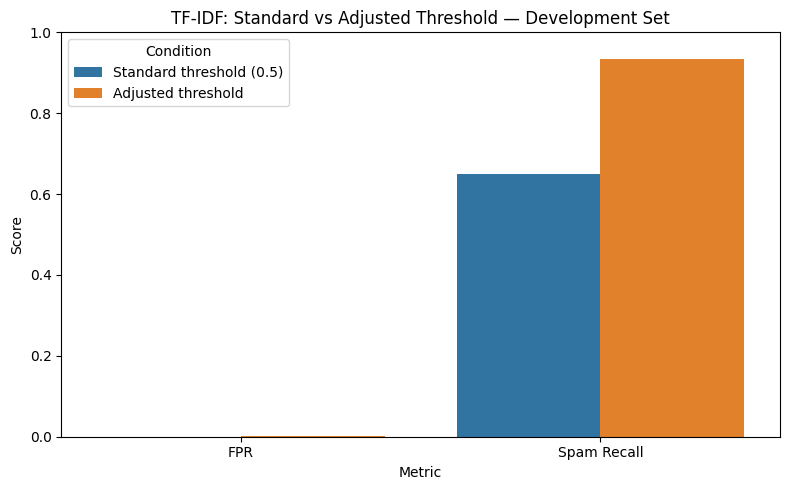

In [21]:
plot_data = development_comparison.melt(
    id_vars="Condition", value_vars=["FPR", "Spam Recall"],
    var_name="Metric", value_name="Score"
)
plt.figure(figsize=(8, 5))
sns.barplot(data=plot_data, x="Metric", y="Score", hue="Condition")
plt.ylim(0, 1)
plt.title("TF-IDF: Standard vs Adjusted Threshold — Development Set")
plt.tight_layout()
plt.show()

## 12. Freeze the threshold and evaluate the held-out TEST set


In [22]:
# Generate test spam probabilities after threshold selection is complete.
tfidf_test_probabilities = tfidf_model.predict_proba(X_test_tfidf)[:, spam_class_index]

test_comparison = pd.DataFrame([
    {"Condition": "Standard threshold (0.5)",
     **evaluate_threshold(test_df.target, tfidf_test_probabilities, 0.5)},
    {"Condition": "Adjusted threshold",
     **evaluate_threshold(test_df.target, tfidf_test_probabilities, adjusted_threshold)}
])
display(test_comparison)

,Condition,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
0,Standard threshold (0.5),0.500000,0.000000,0.655629,0.952381,0.882556,941,0,52,99
1,Adjusted threshold,0.286596,0.006376,0.907285,0.981685,0.960695,935,6,14,137


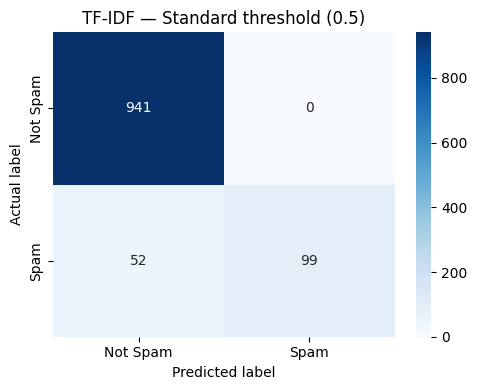

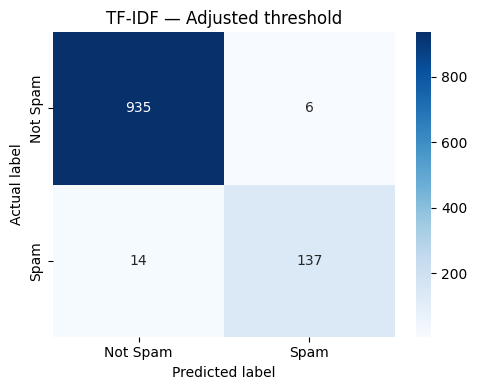

In [23]:
for condition, threshold in [("Standard threshold (0.5)", 0.5),
                            ("Adjusted threshold", adjusted_threshold)]:
    predictions = (tfidf_test_probabilities >= threshold).astype(int)
    cm = confusion_matrix(test_df.target, predictions, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not Spam", "Spam"],
                yticklabels=["Not Spam", "Spam"])
    plt.title("TF-IDF — " + condition)
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.tight_layout()
    plt.show()

In [24]:
#Provide consistent names for the integrated comparison section.
tfidf_dev_probabilities = np.asarray(tfidf_dev_probabilities, dtype=float)
tfidf_test_probabilities = np.asarray(tfidf_test_probabilities, dtype=float)
tfidf_adjusted = float(adjusted_threshold)

assert len(tfidf_dev_probabilities) == len(splits["development"])
assert len(tfidf_test_probabilities) == len(splits["test"])
print("TF-IDF probabilities aligned with the shared development and test rows.")

TF-IDF probabilities aligned with the shared development and test rows.


## Method 2 · Sentence-BERT + Logistic Regression
Keep the pretrained encoder frozen. Encode the cleaned SMS text and train Logistic Regression on training embeddings only. The cache key includes the model, encoder package versions, and ordered text so that embeddings are reused for the matching inputs.

In [25]:
model_id = "sentence-transformers/all-MiniLM-L6-v2"
# Pin the checkpoint so a future update to the repository does not change the embeddings.
model_revision = "c9745ed1d9f207416be6d2e6f8de32d1f16199bf"
encoder = SentenceTransformer(model_id, revision=model_revision, device="cpu")
cache_dir = Path("sbert_embedding_cache")
cache_dir.mkdir(exist_ok=True)

def encode_split(name):
    texts = splits[name]["model_text"].tolist()
    cache_inputs = [model_id, model_revision, version("sentence-transformers"),
                    version("transformers"), version("torch"), texts]
    digest = hashlib.sha256(json.dumps(cache_inputs).encode()).hexdigest()
    cache_file = cache_dir / f"{name}-{digest}.npy"
    if cache_file.exists():
        return np.load(cache_file, allow_pickle=False)
    vectors = encoder.encode(texts, batch_size=64, normalize_embeddings=True,
                             show_progress_bar=True, convert_to_numpy=True)
    temporary = cache_file.with_suffix(".tmp")
    with temporary.open("wb") as stream:
        np.save(stream, vectors, allow_pickle=False)
    temporary.replace(cache_file)
    return vectors

sbert_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
sbert_model.fit(encode_split("train"), splits["train"]["target"])
spam_column = list(sbert_model.classes_).index(1)
sbert_dev_probabilities = sbert_model.predict_proba(encode_split("development"))[:, spam_column]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/57 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

In [26]:

default_threshold = DEFAULT_THRESHOLD
minimum_recall = MIN_SPAM_RECALL
seed = RANDOM_STATE

development_targets = splits["development"]["target"].to_numpy()
test = splits["test"]


assert np.isclose(tfidf_adjusted, adjusted_threshold)
assert len(development_targets) == len(tfidf_dev_probabilities)
assert len(test) == len(tfidf_test_probabilities)

print("Shared in-memory splits and TF-IDF outputs are ready for SBERT comparison.")

Shared in-memory splits and TF-IDF outputs are ready for SBERT comparison.


## Threshold selection


### 14.2 Shared threshold-selection rule



In [27]:

def select_threshold_min_fpr(y_development, development_probability, min_recall):
    if not 0 < min_recall <= 1:
        raise ValueError("Minimum recall must be greater than 0 and at most 1.")

    candidates = np.unique(np.r_[0.0, development_probability, 1.0])
    results = pd.DataFrame([
        evaluate_threshold(y_development, development_probability, threshold)
        for threshold in candidates
    ])

    eligible = results.loc[results["Spam Recall"].ge(min_recall)].sort_values(
        ["FPR", "Spam Recall", "Threshold"],
        ascending=[True, False, False]
    )
    if eligible.empty:
        raise ValueError(
            "No development threshold meets the minimum recall. "
            "Discuss the target; do not tune on test data."
        )

    selected = float(eligible.iloc[0]["Threshold"])
    return selected, results

sbert_adjusted, sbert_threshold_search = select_threshold_min_fpr(
    development_targets, sbert_dev_probabilities, minimum_recall
)

sbert_threshold_eligible = sbert_threshold_search.loc[
    sbert_threshold_search["Spam Recall"].ge(minimum_recall)
].sort_values(["FPR", "Spam Recall", "Threshold"],
              ascending=[True, False, False])

model_thresholds = {
    "TF-IDF": {"Default": default_threshold, "Adjusted": tfidf_adjusted},
    "Sentence-BERT": {"Default": default_threshold, "Adjusted": sbert_adjusted},
}

print("TF-IDF adjusted threshold:", tfidf_adjusted)
print("SBERT adjusted threshold:", sbert_adjusted)
display(sbert_threshold_eligible.head(10))

TF-IDF adjusted threshold: 0.28659602561767433
SBERT adjusted threshold: 0.5910092549040262


,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
734,0.591009,0.000000,0.900000,0.986471,0.969803,767,0,12,108
730,0.568017,0.001304,0.925000,0.988726,0.975206,766,1,9,111
731,0.571670,0.001304,0.916667,0.987599,0.972626,766,1,10,110
732,0.581474,0.001304,0.908333,0.986471,0.970027,766,1,11,109
733,0.583243,0.001304,0.900000,0.985344,0.967409,766,1,12,108
727,0.477435,0.002608,0.941667,0.989853,0.977927,765,2,7,113
728,0.483237,0.002608,0.933333,0.988726,0.975386,765,2,8,112
729,0.556630,0.002608,0.925000,0.987599,0.972826,765,2,9,111
726,0.472382,0.003911,0.941667,0.988726,0.975563,764,3,7,113
723,0.389607,0.006519,0.966667,0.989853,0.978392,762,5,4,116


In [28]:
def compare_conditions(y_true, probabilities_by_model):
    return pd.DataFrame([
        {
            "Model": model,
            "Condition": condition,
            **evaluate_threshold(y_true, probabilities_by_model[model], threshold)
        }
        for model, thresholds in model_thresholds.items()
        for condition, threshold in thresholds.items()
    ])

development_results = compare_conditions(development_targets, {
    "TF-IDF": tfidf_dev_probabilities,
    "Sentence-BERT": sbert_dev_probabilities
})
display(development_results.round(6))

,Model,Condition,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
0,TF-IDF,Default,0.500000,0.000000,0.650000,0.952649,0.880615,767,0,42,78
1,TF-IDF,Adjusted,0.286596,0.001304,0.933333,0.989853,0.977767,766,1,8,112
2,Sentence-BERT,Default,0.500000,0.002608,0.925000,0.987599,0.972826,765,2,9,111
3,Sentence-BERT,Adjusted,0.591009,0.000000,0.900000,0.986471,0.969803,767,0,12,108


## Results · Held-out test comparison


In [29]:

test_probabilities = {
    "TF-IDF": tfidf_test_probabilities,
    "Sentence-BERT": sbert_model.predict_proba(encode_split("test"))[:, spam_column],
}
test_results = compare_conditions(test["target"].to_numpy(), test_probabilities)
display(test_results.round(6))

# MODIFIED: Preserve original dataset row IDs to make test examples traceable.
test_predictions = test[["row_id", "text", "label", "target"]].copy().reset_index(drop=True)
for model, prefix in (("TF-IDF", "tfidf"), ("Sentence-BERT", "sbert")):
    test_predictions[f"{prefix}_spam_probability"] = test_probabilities[model]
    for condition, threshold in model_thresholds[model].items():
        test_predictions[f"{prefix}_{condition.lower()}_prediction"] = (
            test_probabilities[model] >= threshold
        ).astype(int)

Batches:   0%|          | 0/18 [00:00<?, ?it/s]

,Model,Condition,Threshold,FPR,Spam Recall,Accuracy,Macro F1,TN,FP,FN,TP
0,TF-IDF,Default,0.500000,0.000000,0.655629,0.952381,0.882556,941,0,52,99
1,TF-IDF,Adjusted,0.286596,0.006376,0.907285,0.981685,0.960695,935,6,14,137
2,Sentence-BERT,Default,0.500000,0.001063,0.867550,0.980769,0.957374,940,1,20,131
3,Sentence-BERT,Adjusted,0.591009,0.000000,0.827815,0.976190,0.946085,941,0,26,125


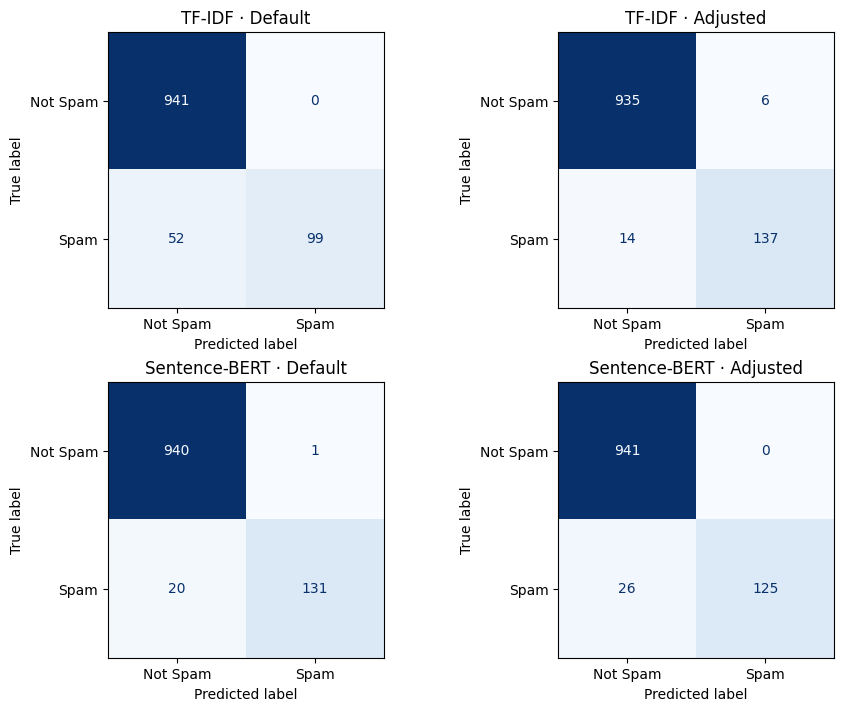

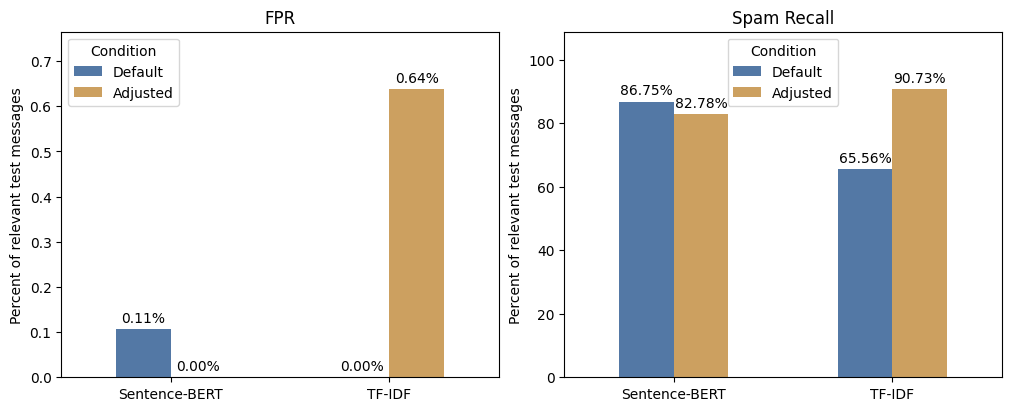

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True)
for ax, row in zip(axes.flat, test_results.to_dict("records")):
    matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]])
    ConfusionMatrixDisplay(matrix, display_labels=["Not Spam", "Spam"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f'{row["Model"]} · {row["Condition"]}')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, metric in zip(axes, ["FPR", "Spam Recall"]):
    percentages = test_results.pivot(index="Model", columns="Condition", values=metric) * 100
    percentages[["Default", "Adjusted"]].plot.bar(ax=ax, rot=0, color=["#5378a5", "#cca060"])
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.2f%%", padding=3)
    ax.set_xlabel("")
    ax.set_ylabel("Percent of relevant test messages")
    ax.set_title(metric)
    ax.margins(y=0.2)
plt.show()

## 15. Error analysis

The following cells extract false positives and false negatives using each model's **adjusted development-selected threshold**. Select at least three actual test errors (or all errors if there are fewer), and explain the true label, predicted label, probability, and likely linguistic reason. Do not change thresholds or keyword lists based on test errors.

In [31]:
error_rows = []
for model, prefix in (("TF-IDF", "tfidf"), ("Sentence-BERT", "sbert")):
    pred_col = f"{prefix}_adjusted_prediction"
    prob_col = f"{prefix}_spam_probability"
    wrong = test_predictions.loc[test_predictions["target"] != test_predictions[pred_col]].copy()

    for _, row in wrong.iterrows():
        error_rows.append({
            "Model": model,
            "row_id": row["row_id"],
            "text": row["text"],
            "true_label": row["label"],
            "predicted_label": "spam" if int(row[pred_col]) == 1 else "ham",
            "spam_probability": float(row[prob_col]),
            "threshold": float(model_thresholds[model]["Adjusted"]),
            "error_type": "False Positive" if int(row["target"]) == 0 else "False Negative",
        })

error_analysis = pd.DataFrame(error_rows)
print("Adjusted-threshold errors by model:")
if not error_analysis.empty:
    display(error_analysis.groupby(["Model", "error_type"]).size().rename("Count").reset_index())
    # MODIFIED: Display all errors separately for each model.
    print("TF-IDF errors:")
    display(
    error_analysis[error_analysis["Model"] == "TF-IDF"]
    .reset_index(drop=True)
)

    print("Sentence-BERT errors:")
    display(
    error_analysis[error_analysis["Model"] == "Sentence-BERT"]
    .reset_index(drop=True)
)

else:
    print("No adjusted-threshold errors were produced on this test split.")

Adjusted-threshold errors by model:


,Model,error_type,Count
0,Sentence-BERT,False Negative,26
1,TF-IDF,False Negative,14
2,TF-IDF,False Positive,6


TF-IDF errors:


,Model,row_id,text,true_label,predicted_label,spam_probability,threshold,error_type
0,TF-IDF,153,Ok... Ur typical reply...,ham,spam,0.322190,0.286596,False Positive
1,TF-IDF,529,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750,spam,ham,0.203137,0.286596,False Negative
2,TF-IDF,1500,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO",spam,ham,0.186398,0.286596,False Negative
3,TF-IDF,1940,More people are dogging in your area now. Call 09090204448 and join like minded guys. Why not arrange 1 yourself. There's 1 this evening. A£1.50 minAPN LS278BB,spam,ham,0.244850,0.286596,False Negative
4,TF-IDF,2248,Back 2 work 2morro half term over! Can U C me 2nite 4 some sexy passion B4 I have 2 go back? Chat NOW 09099726481 Luv DENA Calls £1/minMobsmoreLKPOBOX177HP51FL,spam,ham,0.137089,0.286596,False Negative
5,TF-IDF,2575,Your next amazing xxx PICSFREE1 video will be sent to you enjoy! If one vid is not enough for 2day text back the keyword PICSFREE1 to get the next video.,spam,ham,0.267357,0.286596,False Negative
6,TF-IDF,2699,FROM 88066 LOST £12 HELP,spam,ham,0.212254,0.286596,False Negative
7,TF-IDF,2821,INTERFLORA - It's not too late to order Interflora flowers for christmas call 0800 505060 to place your order before Midnight tomorrow.,spam,ham,0.208849,0.286596,False Negative
8,TF-IDF,2823,ROMCAPspam Everyone around should be responding well to your presence since you are so warm and outgoing. You are bringing in a real breath of sunshine.,spam,ham,0.100802,0.286596,False Negative
9,TF-IDF,2965,"Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving faster than you is a maniac?",spam,ham,0.045153,0.286596,False Negative


Sentence-BERT errors:


,Model,row_id,text,true_label,predicted_label,spam_probability,threshold,error_type
0,Sentence-BERT,235,Text & meet someone sexy today. U can find a date or even flirt its up to U. Join 4 just 10p. REPLY with NAME & AGE eg Sam 25. 18 -msg recd@thirtyeight pence,spam,ham,0.263808,0.591009,False Negative
1,Sentence-BERT,529,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750,spam,ham,0.228956,0.591009,False Negative
2,Sentence-BERT,1172,"Got what it takes 2 take part in the WRC Rally in Oz? U can with Lucozade Energy! Text RALLY LE to 61200 (25p), see packs or lucozade.co.uk/wrc & itcould be u!",spam,ham,0.159122,0.591009,False Negative
3,Sentence-BERT,1374,"Bears Pic Nick, and Tom, Pete and ... Dick. In fact, all types try gay chat with photo upload call 08718730666 (10p/min). 2 stop texts call 08712460324",spam,ham,0.237068,0.591009,False Negative
4,Sentence-BERT,1500,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply ANS w/question. End? Reply END JSCO",spam,ham,0.056974,0.591009,False Negative
5,Sentence-BERT,1880,U have a secret admirer who is looking 2 make contact with U-find out who they R*reveal who thinks UR so special-call on 09058094594,spam,ham,0.519632,0.591009,False Negative
6,Sentence-BERT,2115,"Sunshine Hols. To claim ur med holiday send a stamped self address envelope to Drinks on Us UK, PO Box 113, Bray, Wicklow, Eire. Quiz Starts Saturday! Unsub...",spam,ham,0.353573,0.591009,False Negative
7,Sentence-BERT,2145,FreeMsg: Hey - I'm Buffy. 25 and love to satisfy men. Home alone feeling randy. Reply 2 C my PIX! QlynnBV Help08700621170150p a msg Send stop to stop txts,spam,ham,0.493750,0.591009,False Negative
8,Sentence-BERT,2146,"Sunshine Hols. To claim ur med holiday send a stamped self address envelope to Drinks on Us UK, PO Box 113, Bray, Wicklow, Eire. Quiz Starts Saturday! Unsub...",spam,ham,0.353573,0.591009,False Negative
9,Sentence-BERT,2248,Back 2 work 2morro half term over! Can U C me 2nite 4 some sexy passion B4 I have 2 go back? Chat NOW 09099726481 Luv DENA Calls £1/minMobsmoreLKPOBOX177HP51FL,spam,ham,0.242393,0.591009,False Negative


## 16. Challenge-subset evaluation

The challenge subset is defined as **legitimate (ham) test messages containing at least one agreed spam-associated keyword**. The keyword list must be finalized independently of test-set outcomes. Until the team confirms the list, this section deliberately skips the calculation.

In [32]:

challenge_results = pd.DataFrame()

if not CHALLENGE_KEYWORDS_CONFIRMED:
    print(
        "Challenge-subset results skipped. Finalize SPAM_ASSOCIATED_KEYWORDS "
        "with the team, then set CHALLENGE_KEYWORDS_CONFIRMED = True and rerun."
    )
elif not SPAM_ASSOCIATED_KEYWORDS:
    raise ValueError("The confirmed challenge keyword list cannot be empty.")
else:
    keyword_pattern = re.compile(
        r"\b(?:" + "|".join(re.escape(word) for word in SPAM_ASSOCIATED_KEYWORDS) + r")\b",
        flags=re.IGNORECASE
    )
    challenge_mask = (
        test_predictions["target"].eq(0)
        & test_predictions["text"].str.contains(keyword_pattern, na=False)
    )
    challenge_subset = test_predictions.loc[challenge_mask].copy()

    if challenge_subset.empty:
        print("No legitimate test messages match the confirmed challenge keywords.")
    else:
        challenge_rows = []
        for model, prefix in (("TF-IDF", "tfidf"), ("Sentence-BERT", "sbert")):
            for condition, threshold in model_thresholds[model].items():
                prediction_col = f"{prefix}_{condition.lower()}_prediction"
                false_positives = int(challenge_subset[prediction_col].sum())
                challenge_rows.append({
                    "Model": model,
                    "Condition": condition,
                    "Challenge ham examples": len(challenge_subset),
                    "False positives": false_positives,
                    "Challenge FPR": false_positives / len(challenge_subset)
                })
        challenge_results = pd.DataFrame(challenge_rows)
        print("Challenge subset size:", len(challenge_subset))
        print("Confirmed keywords:", SPAM_ASSOCIATED_KEYWORDS)
        display(challenge_results)

Challenge subset size: 30
Confirmed keywords: ['free', 'win', 'urgent', 'cash', 'offer', 'reply']


,Model,Condition,Challenge ham examples,False positives,Challenge FPR
0,TF-IDF,Default,30,0,0.0
1,TF-IDF,Adjusted,30,3,0.1
2,Sentence-BERT,Default,30,0,0.0
3,Sentence-BERT,Adjusted,30,0,0.0


## 17. Try it — predict a new SMS without retraining

This section uses the fitted vectorizer, fitted Logistic Regression classifiers, and the frozen pretrained Sentence-BERT encoder. It does not call `.fit()` or change either threshold.

In [33]:
def predict_new_sms(message):
    if not isinstance(message, str) or not message.strip():
        print("Please enter a non-empty SMS message.")
        return

    # TF-IDF path
    tfidf_features = tfidf_vectorizer.transform([message])
    tfidf_spam_probability = tfidf_model.predict_proba(tfidf_features)[0, spam_class_index]

    # Sentence-BERT path
    sbert_embedding = encoder.encode(
        [message],
        batch_size=1,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=False
    )
    sbert_spam_probability = sbert_model.predict_proba(sbert_embedding)[0, spam_column]

    print(f"Message: {message}")
    print(
        f"TF-IDF: P(Spam)={tfidf_spam_probability:.3f} | "
        f"Default={'Spam' if tfidf_spam_probability >= default_threshold else 'Not Spam'} | "
        f"Adjusted={'Spam' if tfidf_spam_probability >= tfidf_adjusted else 'Not Spam'}"
    )
    print(
        f"SBERT:  P(Spam)={sbert_spam_probability:.3f} | "
        f"Default={'Spam' if sbert_spam_probability >= default_threshold else 'Not Spam'} | "
        f"Adjusted={'Spam' if sbert_spam_probability >= sbert_adjusted else 'Not Spam'}"
    )

print("SMS Spam Detection System")
print("Enter an SMS message to classify.")
print("Type 'exit' to stop testing.\n")

while True:
    user_message = input("Enter SMS: ")

    if user_message.strip().lower() in ["exit", "quit"]:
        print("Testing session ended.")
        break

    predict_new_sms(user_message)
    print("-" * 60)

SMS Spam Detection System
Enter an SMS message to classify.
Type 'exit' to stop testing.

Enter SMS: Are you free at 4 to practice our presentation in the library?
Message: Are you free at 4 to practice our presentation in the library?
TF-IDF: P(Spam)=0.165 | Default=Not Spam | Adjusted=Not Spam
SBERT:  P(Spam)=0.020 | Default=Not Spam | Adjusted=Not Spam
------------------------------------------------------------
Enter SMS: URGENT! Your number was selected for a free weekend trip. Reply WIN today to claim your prize.
Message: URGENT! Your number was selected for a free weekend trip. Reply WIN today to claim your prize.
TF-IDF: P(Spam)=0.870 | Default=Spam | Adjusted=Spam
SBERT:  P(Spam)=0.907 | Default=Spam | Adjusted=Spam
------------------------------------------------------------
Enter SMS: exit
Testing session ended.


## 18. Original labelled examples — individual contribution

The course guidelines require two original labelled SMS examples from each member. Add examples created by each member here, separate from the held-out test data. Do not present these as test-set results.

In [34]:
original_examples = pd.DataFrame([
     {"Member": "Raneem",
      "text": "Feel free to send me the lecture slides when you get home. I need them for tomorrow's class.",
      "label": "ham"},

    {"Member": "Raneem",
     "text": "Congratulations! You have won a shopping voucher worth $500. Reply CLAIM now to receive your prize.",
     "label": "spam"},

    {"Member": "Alaa",
     "text": "Are you free at 4 to practice our presentation in the library?",
     "label": "ham"},

    {"Member": "Alaa",
     "text": "URGENT! Your number was selected for a free weekend trip. Reply WIN today to claim your prize.",
     "label": "spam"},

], columns=["Member", "text", "label"])
display(original_examples)

,Member,text,label
0,Raneem,Feel free to send me the lecture slides when you get home. I need them for tomorrow's class.,ham
1,Raneem,Congratulations! You have won a shopping voucher worth $500. Reply CLAIM now to receive your prize.,spam
2,Alaa,Are you free at 4 to practice our presentation in the library?,ham
3,Alaa,URGENT! Your number was selected for a free weekend trip. Reply WIN today to claim your prize.,spam


## 19. Save results, models, settings, and environment versions

This section exports the shared split, both models' development/test results, test predictions, error review, thresholds, and library versions. The Sentence-BERT encoder is identified by its pinned model revision and can be downloaded again when the notebook is rerun.

In [35]:
# Export one complete and reproducible result bundle for the group.
output = Path("group8_evaluation")
output.mkdir(exist_ok=True)

# Shared split assignments for independent verification/reuse.
shared_split_assignments.to_csv(output / "shared_split_assignments.csv", index=False)

# Both methods' metrics and their raw test probabilities/predictions.
development_results.to_csv(output / "development_comparison.csv", index=False)
test_results.to_csv(output / "test_comparison.csv", index=False)
test_predictions.to_csv(output / "test_predictions.csv", index=False)
error_analysis.to_csv(output / "test_error_analysis.csv", index=False)
sbert_threshold_search.to_csv(output / "sbert_development_threshold_search.csv", index=False)
sbert_threshold_eligible.to_csv(output / "sbert_development_eligible_thresholds.csv", index=False)

# Preserve TF-IDF's original threshold search outputs as well.
all_dev_thresholds.to_csv(output / "tfidf_development_threshold_search.csv", index=False)
eligible_thresholds.to_csv(output / "tfidf_development_eligible_thresholds.csv", index=False)

if not challenge_results.empty:
    challenge_results.to_csv(output / "challenge_subset_results.csv", index=False)
if not original_examples.empty:
    original_examples.to_csv(output / "original_labelled_examples.csv", index=False)

# Save fitted classifiers and vectorizer. The frozen SBERT encoder is reloaded
# from its pinned checkpoint using model_id and model_revision above.
joblib.dump(tfidf_vectorizer, output / "tfidf_vectorizer.joblib")
joblib.dump(tfidf_model, output / "tfidf_logistic_regression.joblib")
joblib.dump(sbert_model, output / "sbert_logistic_regression.joblib")

experiment_settings = {
    "minimum_development_spam_recall": float(MIN_SPAM_RECALL),
    "standard_threshold": float(DEFAULT_THRESHOLD),
    "tfidf_adjusted_threshold": float(tfidf_adjusted),
    "sbert_adjusted_threshold": float(sbert_adjusted),
    "threshold_selection_rule": "Minimize development FPR subject to minimum development Spam Recall; tie-break by higher Spam Recall, then higher threshold.",
    "random_state": int(RANDOM_STATE),
    "test_size_of_unique_groups": float(TEST_SIZE),
    "development_size_of_train_dev_groups": float(DEV_SIZE_OF_REMAINDER),
    "sbert_model_id": model_id,
    "sbert_model_revision": model_revision,
    "challenge_keywords": SPAM_ASSOCIATED_KEYWORDS,
    "challenge_keywords_confirmed": bool(CHALLENGE_KEYWORDS_CONFIRMED),
}
(output / "experiment_settings.json").write_text(json.dumps(experiment_settings, indent=2))

packages = [
    "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "joblib",
    "sentence-transformers", "transformers", "torch"
]
environment_versions = {name: version(name) for name in packages}
(output / "environment_versions.json").write_text(json.dumps(environment_versions, indent=2))

print("Saved files to:", output.resolve())
print("Environment versions:", environment_versions)

Saved files to: /content/group8_evaluation
Environment versions: {'pandas': '2.2.3', 'numpy': '2.4.6', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'sentence-transformers': '6.3.0', 'transformers': '5.22.1', 'torch': '2.14.1+cpu'}


In [36]:
#Create one ZIP package containing the integrated group's outputs.
zip_path = Path("Group8_SMS_Spam_Detection_Results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in sorted(output.iterdir()):
        if file_path.is_file():
            archive.write(file_path, arcname=f"group8_evaluation/{file_path.name}")

print("Created:", zip_path.resolve())
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

# In Google Colab, uncomment the following lines to download the result bundle.
#from google.colab import files
#files.download(str(zip_path))

Created: /content/Group8_SMS_Spam_Detection_Results.zip
ZIP size (MB): 0.97


## 20. Sources

- Dataset: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)
- Pretrained encoder: [sentence-transformers/all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- Sentence-BERT paper: [Reimers and Gurevych (2019)](https://aclanthology.org/D19-1410/)
- Libraries: [Sentence-Transformers](https://www.sbert.net/) · [scikit-learn](https://scikit-learn.org/stable/)
- ChatGPT assisted with drafting and checking parts of the Sentence-BERT and evaluation code and suggested two synthetic SMS examples for the demo.

